# 02 — EDA Logística | Case NPS Preditivo (Tech Challenge Fase 1)

## 01. Objetivo da análise

**Contexto.** Uma empresa de e-commerce em crescimento acelerado enfrenta alta variabilidade do NPS: com indicadores operacionais aparentemente parecidos, alguns clientes viram promotores e outros detratores. O NPS só é coletado *após* o fim da jornada, o que impede ações preventivas. A pergunta central do Tech Challenge é: **quais fatores operacionais realmente influenciam a satisfação e como agir antes da pesquisa?**

**Objetivo desta EDA.** Investigar, de forma exclusiva, a **dimensão logística** da base (entrega, atraso, tentativas e frete) e sua relação com a satisfação (`nota_nps`), para:

1. entender como está a operação de entrega;
2. identificar padrões, gargalos e segmentos críticos;
3. separar o que **importa** do que **não importa** para a satisfação;
4. indicar variáveis candidatas para a etapa de Machine Learning.

**Por que logística importa?** É o ponto de contato físico entre a promessa da loja e a experiência do cliente. Atrasos, falhas de entrega e frete são a parte da jornada mais controlável pela operação e, portanto, a mais acionável.

**Perguntas de negócio**

- Como se distribuem tempo de entrega, atraso, tentativas e frete?
- A operação difere entre regiões?
- Quais variáveis logísticas se associam a pior (ou melhor) NPS?
- Existe um "ponto de ruptura" a partir do qual o cliente vira detrator?
- Quais segmentos concentram o maior volume de detratores?
- Quais variáveis logísticas valem a pena para um modelo preditivo?

> **Convenção do notebook:** usamos os rótulos **Fato** (observado nos dados), **Hipótese**, **Interpretação** e **Recomendação** para separar o que é evidência do que é inferência.

### Leitura prévia da estrutura da base (antes de qualquer código)

Com base no **Dicionário de Dados** e no documento do Tech Challenge, a classificação das colunas é:

| Grupo | Colunas | Observação |
|---|---|---|
| **Identificadores** | `id_cliente`, `id_pedido` | Chaves; sem valor preditivo. |
| **Logística (foco)** | `tempo_entrega_dias`, `atraso_entrega_dias`, `valor_frete`, `tentativas_entrega` | Citadas explicitamente no dicionário como candidatas fortes. |
| **Atendimento (contexto)** | `contatos_atendimento`, `tempo_resolucao_dias`, `qtd_reclamacoes` | Fora do escopo, mas usadas para verificar se atraso "vaza" para o atendimento. |
| **Pedido (contexto)** | `valor_pedido`, `qtd_itens`, `valor_desconto`, `parcelas_pagamento` | Usadas só para checar se o perfil do pedido afeta a logística. |
| **Cliente / localização** | `idade_cliente`, `tempo_relacionamento_meses`, `regiao_cliente` | **Única variável de localização é a região do *cliente*** (5 categorias). |
| **Variável temporal** | — | **Não existe.** Nenhuma coluna de data na base. |
| **Target / resultados** | `nota_nps` (target), `csat_interno`, `recompra_30d` | `csat` e recompra são resultados de satisfação, não features logísticas. |

**O que NÃO existe na base** (portanto não será analisado): datas, centro de distribuição, rota/origem, produto/categoria/SKU, transportadora, modalidade de entrega e estoque. As seções correspondentes (06, 08, 09, 11 e parte da 10) trazem o aviso explícito exigido.

## 02. Importação das bibliotecas

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats  # usado apenas para testes estatísticos pontuais (Kruskal-Wallis, Spearman)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 03. Carregamento e entendimento inicial dos dados

In [2]:
CAMINHO = Path("../data/processed/desafio_nps_fase_1_clean.csv")
    
MAPA_COLUNAS = {
    "customer_id": "id_cliente",
    "customer_age": "idade_cliente",
    "customer_region": "regiao_cliente",
    "customer_tenure_months": "tempo_relacionamento_meses",
    "order_id": "id_pedido",
    "order_value": "valor_pedido",
    "items_quantity": "qtd_itens",
    "discount_value": "valor_desconto",
    "payment_installments": "parcelas_pagamento",
    "delivery_time_days": "tempo_entrega_dias",
    "delivery_delay_days": "atraso_entrega_dias",
    "freight_value": "valor_frete",
    "delivery_attempts": "tentativas_entrega",
    "customer_service_contacts": "contatos_atendimento",
    "resolution_time_days": "tempo_resolucao_dias",
    "complaints_count": "qtd_reclamacoes",
    "repeat_purchase_30d": "recompra_30d",
    "csat_internal_score": "csat_interno",
    "nps_score": "nota_nps",
}

df_bruto = pd.read_csv(CAMINHO)  
df = df_bruto.rename(columns=MAPA_COLUNAS)

print(f"Arquivo: {CAMINHO}")
print(f"Dimensões: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Memória: {df.memory_usage(deep=True).sum() / 1024:,.1f} KB")
df.head()

Arquivo: ..\data\processed\desafio_nps_fase_1_clean.csv
Dimensões: 2,465 linhas x 19 colunas
Memória: 481.3 KB


,id_cliente,idade_cliente,regiao_cliente,tempo_relacionamento_meses,id_pedido,valor_pedido,qtd_itens,valor_desconto,parcelas_pagamento,tempo_entrega_dias,atraso_entrega_dias,valor_frete,tentativas_entrega,contatos_atendimento,tempo_resolucao_dias,nota_nps,recompra_30d,qtd_reclamacoes,csat_interno
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.90,0,3,6.50
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.40,0,3,0.00
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.80,0,7,1.50
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.90,0,4,0.30
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.10,0,3,7.90


**Nomes das colunas em português.** Para facilitar a leitura de tabelas e gráficos, as colunas do CSV são renomeadas logo após a leitura (`df_bruto` guarda a versão original). Correspondência:

| Original (CSV / dicionário) | Neste notebook |
|---|---|
| `customer_id` | `id_cliente` |
| `customer_age` | `idade_cliente` |
| `customer_region` | `regiao_cliente` |
| `customer_tenure_months` | `tempo_relacionamento_meses` |
| `order_id` | `id_pedido` |
| `order_value` | `valor_pedido` |
| `items_quantity` | `qtd_itens` |
| `discount_value` | `valor_desconto` |
| `payment_installments` | `parcelas_pagamento` |
| `delivery_time_days` | `tempo_entrega_dias` |
| `delivery_delay_days` | `atraso_entrega_dias` |
| `freight_value` | `valor_frete` |
| `delivery_attempts` | `tentativas_entrega` |
| `customer_service_contacts` | `contatos_atendimento` |
| `resolution_time_days` | `tempo_resolucao_dias` |
| `complaints_count` | `qtd_reclamacoes` |
| `repeat_purchase_30d` | `recompra_30d` |
| `csat_internal_score` | `csat_interno` |
| `nps_score` | `nota_nps` |

In [3]:
def montar_tabela_esquema(quadro: pd.DataFrame) -> pd.DataFrame:
    """Resumo por coluna: tipo, nulos, % nulos e valores únicos."""
    return pd.DataFrame({
        "tipo": quadro.dtypes.astype(str),
        "qtd_nulos": quadro.isna().sum(),
        "pct_nulos": quadro.isna().mean() * 100,
        "qtd_unicos": quadro.nunique(),
    })

esquema = montar_tabela_esquema(df)
esquema

,tipo,qtd_nulos,pct_nulos,qtd_unicos
id_cliente,int64,0,0.00,2465
idade_cliente,int64,0,0.00,52
regiao_cliente,object,0,0.00,5
tempo_relacionamento_meses,int64,0,0.00,119
id_pedido,int64,0,0.00,2465
valor_pedido,float64,0,0.00,2423
qtd_itens,int64,0,0.00,6
valor_desconto,float64,0,0.00,2020
parcelas_pagamento,int64,0,0.00,11
tempo_entrega_dias,int64,0,0.00,13


In [4]:
# Identificação de IDs: colunas em que todo valor é único
candidatos_id = [c for c in df.columns if df[c].is_unique]
print("Colunas com valores 100% únicos (possíveis IDs):", candidatos_id)

# Agrupamento semântico das colunas (conforme dicionário de dados)
ALVO = "nota_nps"
COLS_ID = ["id_cliente", "id_pedido"]
COLS_LOGISTICA = ["tempo_entrega_dias", "atraso_entrega_dias", "valor_frete", "tentativas_entrega"]
COLS_ATENDIMENTO = ["contatos_atendimento", "tempo_resolucao_dias", "qtd_reclamacoes"]
COLS_PEDIDO = ["valor_pedido", "qtd_itens", "valor_desconto", "parcelas_pagamento"]
COLS_CLIENTE = ["idade_cliente", "tempo_relacionamento_meses", "regiao_cliente"]
COLS_RESULTADO = ["csat_interno", "recompra_30d"]

assert set(COLS_ID + COLS_LOGISTICA + COLS_ATENDIMENTO + COLS_PEDIDO + COLS_CLIENTE + COLS_RESULTADO + [ALVO]) == set(df.columns)

df[COLS_LOGISTICA + [ALVO]].describe().T

Colunas com valores 100% únicos (possíveis IDs): ['id_cliente', 'id_pedido']


,count,mean,std,min,25%,50%,75%,max
tempo_entrega_dias,"2,465.00",8.02,3.77,2.00,5.00,8.00,11.00,14.00
atraso_entrega_dias,"2,465.00",2.19,1.46,0.00,1.00,2.00,3.00,8.00
valor_frete,"2,465.00",38.29,12.09,2.62,30.05,38.67,46.33,76.13
tentativas_entrega,"2,465.00",2.01,0.82,1.00,1.00,2.00,3.00,3.00
nota_nps,"2,465.00",4.38,2.51,0.00,2.60,4.40,6.10,10.00


**Fato.** A base tem 2.465 pedidos (um por cliente), 19 colunas, **nenhum valor nulo** e `id_cliente`/`id_pedido` únicos. Há 4 variáveis logísticas, todas numéricas. `tentativas_entrega` tem só 3 valores (1, 2, 3) e `atraso_entrega_dias` varia de 0 a 8 dias.

**Fato.** O dicionário descreve `nota_nps` como inteiro de 0 a 10, mas a base traz valores **decimais** (ex.: 6,9; 2,4). Isso é tratado na seção de qualidade.

## 04. Qualidade dos dados

### 4.1 Valores ausentes e duplicidades

In [5]:
print("Total de nulos na base:", int(df.isna().sum().sum()))
print("Linhas totalmente duplicadas:", int(df.duplicated().sum()))
for coluna in COLS_ID:
    print(f"Duplicidades em {coluna}: {int(df[coluna].duplicated().sum())}")

# Duplicidade por combinação de atributos do pedido (possível pedido lançado duas vezes com IDs distintos)
chave_negocio = [c for c in df.columns if c not in COLS_ID]
print("Duplicidades considerando todas as colunas exceto IDs:", int(df.duplicated(subset=chave_negocio).sum()))

Total de nulos na base: 0
Linhas totalmente duplicadas: 0
Duplicidades em id_cliente: 0
Duplicidades em id_pedido: 0
Duplicidades considerando todas as colunas exceto IDs: 0


**Fato.** Não há nulos, linhas duplicadas, IDs repetidos nem pedidos idênticos com IDs diferentes.
**Interpretação.** O arquivo se chama `_clean`, o que é coerente: a base já passou por tratamento prévio. Mesmo assim, nulos ausentes não garantem consistência lógica — verificamos isso a seguir.

### 4.2 Valores inconsistentes, impossíveis ou fora do domínio

In [6]:
verificacoes = {}

# Categorias / strings
verificacoes["region: strings vazias"] = int((df["regiao_cliente"].str.strip() == "").sum())
verificacoes["region: espaços sobrando"] = int((df["regiao_cliente"] != df["regiao_cliente"].str.strip()).sum())
verificacoes["region: nº de categorias"] = df["regiao_cliente"].nunique()

# Negativos indevidos (todas as colunas numéricas, exceto IDs)
cols_numericas = df.select_dtypes("number").columns.difference(COLS_ID)
verificacoes["valores negativos (qualquer coluna numérica)"] = int((df[cols_numericas] < 0).sum().sum())

# Domínios
verificacoes["nps fora de [0,10]"] = int((~df["nota_nps"].between(0, 10)).sum())
verificacoes["csat fora de [0,10]"] = int((~df["csat_interno"].between(0, 10)).sum())
verificacoes["tentativas_entrega fora de {1,2,3}"] = int((~df["tentativas_entrega"].isin([1, 2, 3])).sum())
verificacoes["recompra_30d fora de {0,1}"] = int((~df["recompra_30d"].isin([0, 1])).sum())
verificacoes["nota_nps não inteiro (dicionário diz inteiro)"] = int((df["nota_nps"] % 1 != 0).sum())

# Coerência lógica
verificacoes["desconto > valor do pedido"] = int((df["valor_desconto"] > df["valor_pedido"]).sum())
verificacoes["frete > valor do pedido"] = int((df["valor_frete"] > df["valor_pedido"]).sum())
verificacoes["atraso > tempo total de entrega"] = int((df["atraso_entrega_dias"] > df["tempo_entrega_dias"]).sum())
verificacoes["atraso == tempo total de entrega"] = int((df["atraso_entrega_dias"] == df["tempo_entrega_dias"]).sum())

pd.Series(verificacoes, name="ocorrências").to_frame()

,ocorrências
region: strings vazias,0
region: espaços sobrando,0
region: nº de categorias,5
valores negativos (qualquer coluna numérica),0
"nps fora de [0,10]",0
"csat fora de [0,10]",0
"tentativas_entrega fora de {1,2,3}",0
"recompra_30d fora de {0,1}",0
nota_nps não inteiro (dicionário diz inteiro),2045
desconto > valor do pedido,0


In [7]:
print("Regiões:", sorted(df["regiao_cliente"].unique()))
print(f"\n% de nota_nps inteiro: {(df['nota_nps'] % 1 == 0).mean():.1%}")
print(f"% de pedidos com atraso == 0: {(df['atraso_entrega_dias'] == 0).mean():.1%}")
print(f"% de pedidos com atraso > 0: {(df['atraso_entrega_dias'] > 0).mean():.1%}")

Regiões: ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']

% de nota_nps inteiro: 17.0%
% de pedidos com atraso == 0: 11.0%
% de pedidos com atraso > 0: 89.0%


**Fatos**

- Regiões têm 5 categorias, sem grafias duplicadas, espaços ou strings vazias.
- Nenhum valor negativo, nenhum NPS/CSAT fora de 0–10, nenhum desconto ou frete maior que o valor do pedido (frete maior que o pedido ocorre em 8 casos — pedidos de valor baixo, plausíveis).
- **`nota_nps` não é inteiro** em ~83% das linhas, apesar do dicionário.
- **119 pedidos (4,8%) têm `atraso_entrega_dias` maior que `tempo_entrega_dias`**, e outros 144 têm atraso igual ao tempo total.

**Interpretação / Hipótese.** Se `atraso = tempo real − prazo prometido`, então `prazo prometido = tempo − atraso` e deveria ser > 0. Em 263 pedidos esse prazo implícito seria ≤ 0, o que é impossível. Além disso, `tempo_entrega_dias` e `atraso_entrega_dias` têm correlação ≈ 0 (visto na seção 12). Duas hipóteses: **(H1)** o atraso foi medido contra outra referência (ex.: data de postagem, SLA interno) e não contra o tempo total informado; **(H2)** os campos foram gerados/tratados de forma independente. **Não conseguimos decidir com a base disponível** — é uma pergunta a ser levada ao dono dos dados.

**Decisão.** Não removemos esses registros: o atraso é a variável mais importante da análise e a inconsistência pode ser de definição, não de valor. Mantemos as análises e **tratamos `tempo_entrega_dias` e `atraso_entrega_dias` como medidas independentes**, com a ressalva registrada.

**Sobre `nota_nps` decimal:** pode ser média de várias respostas, nota ponderada ou escala contínua. Para classificar em detrator/neutro/promotor **assumimos arredondamento ao inteiro mais próximo** antes de aplicar os cortes do dicionário (premissa explicitada no código abaixo; a mudança de regra altera os percentuais, mas não a direção das conclusões).

In [8]:
# Classificação NPS. O dicionário define 0-6 / 7-8 / 9-10 para notas INTEIRAS, mas a base tem notas decimais.
# Premissa adotada: arredondar a nota ao inteiro mais próximo antes de aplicar os cortes do dicionário:
#   detrator  : nps <  6.5   (arredonda para 0-6)
#   neutro    : 6.5 <= nps < 8.5 (arredonda para 7-8)
#   promotor  : nps >= 8.5   (arredonda para 9-10)
# Esta é uma premissa nossa, não do dicionário; o relatório deve ser reavaliado se a regra oficial for outra.
df["classe_nps"] = pd.cut(
    df["nota_nps"], bins=[-np.inf, 6.5, 8.5, np.inf], labels=["Detrator", "Neutro", "Promotor"], right=False
)
df["eh_detrator"] = (df["classe_nps"] == "Detrator").astype(int)

participacao_classes = df["classe_nps"].value_counts(normalize=True).reindex(["Detrator", "Neutro", "Promotor"]) * 100
valor_nps = participacao_classes["Promotor"] - participacao_classes["Detrator"]
print(participacao_classes.round(1).to_string())
print(f"\nNPS (promotores% - detratores%): {valor_nps:.1f}")

classe_nps
Detrator   79.10
Neutro     14.80
Promotor    6.10

NPS (promotores% - detratores%): -72.9


**Fato.** Com essa regra, aproximadamente **79% dos clientes são detratores**, 15% neutros e só ~6% promotores, o que leva a um NPS muito negativo (≈ −73). A nota média é 4,4.
**Interpretação.** É um cenário de insatisfação generalizada, não de alguns casos isolados. Isso pesa nas análises seguintes: com tão pouco "contraste" (quase todos são detratores), o que importa é **o que diferencia o detrator moderado do muito insatisfeito, e o pouco que consegue ser promotor**.

### 4.3 Outliers nas variáveis logísticas

Método: regra de Tukey (1,5 × IQR) apenas para **sinalizar**. Nada é removido automaticamente; cada caso é classificado como (1) erro de dados, (2) evento raro ou (3) comportamento operacional legítimo.

In [9]:
def resumo_outliers_iqr(quadro: pd.DataFrame, columns: list) -> pd.DataFrame:
    linhas = []
    for coluna in columns:
        q1, q3 = quadro[coluna].quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (quadro[coluna] < lim_inf) | (quadro[coluna] > lim_sup)
        linhas.append({
            "variavel": coluna, "minimo": quadro[coluna].min(), "q1": q1, "mediana": quadro[coluna].median(), "q3": q3,
            "maximo": quadro[coluna].max(), "limite_inferior": lim_inf, "limite_superior": lim_sup,
            "qtd_outliers": int(mask.sum()), "pct_outliers": mask.mean() * 100,
        })
    return pd.DataFrame(linhas).set_index("variavel")

resumo_outliers_iqr(df, COLS_LOGISTICA + ["tempo_resolucao_dias"])

,minimo,q1,mediana,q3,maximo,limite_inferior,limite_superior,qtd_outliers,pct_outliers
variavel,,,,,,,,,
tempo_entrega_dias,2.00,5.00,8.00,11.00,14.00,-4.00,20.00,0,0.00
atraso_entrega_dias,0.00,1.00,2.00,3.00,8.00,-2.00,6.00,17,0.69
valor_frete,2.62,30.05,38.67,46.33,76.13,5.63,70.75,13,0.53
tentativas_entrega,1.00,1.00,2.00,3.00,3.00,-2.00,6.00,0,0.00
tempo_resolucao_dias,0.00,2.00,6.00,8.00,11.00,-7.00,17.00,0,0.00


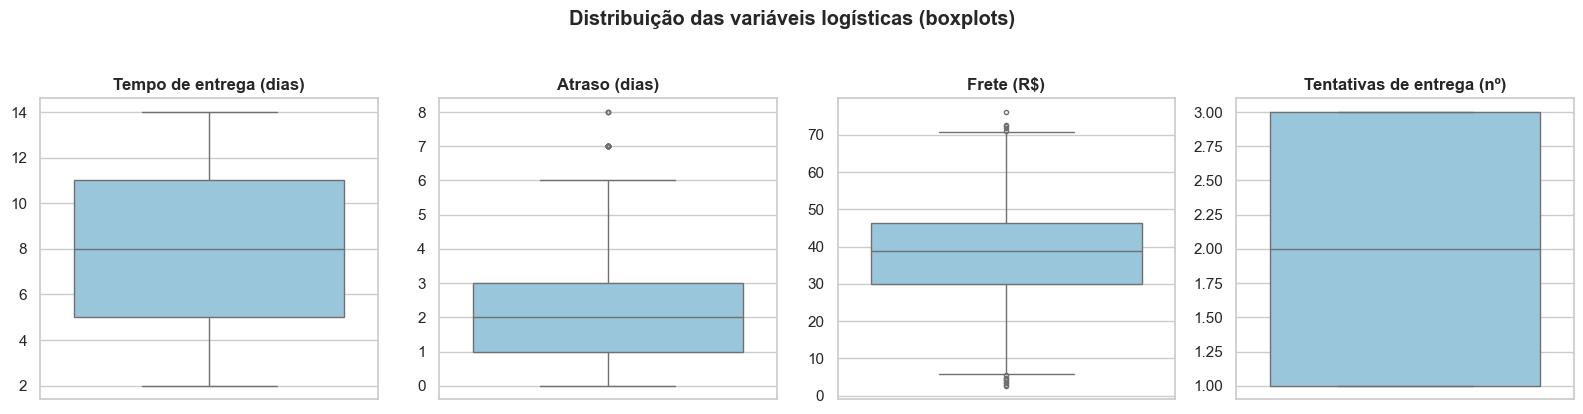

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
rotulos = {
    "tempo_entrega_dias": "Tempo de entrega (dias)",
    "atraso_entrega_dias": "Atraso (dias)",
    "valor_frete": "Frete (R$)",
    "tentativas_entrega": "Tentativas de entrega (nº)",
}
for ax, coluna in zip(axes, COLS_LOGISTICA):
    sns.boxplot(y=df[coluna], ax=ax, color="#8ecae6", fliersize=3)
    ax.set_title(rotulos[coluna]); ax.set_ylabel("")
fig.suptitle("Distribuição das variáveis logísticas (boxplots)", y=1.03, fontweight="bold")
plt.tight_layout(); plt.show()

In [11]:
# Inspeção dos casos sinalizados em atraso e frete
atraso_extremo = df[df["atraso_entrega_dias"] >= 7]
print(f"Atraso >= 7 dias: {len(atraso_extremo)} pedidos | NPS médio {atraso_extremo['nota_nps'].mean():.2f} "
      f"| tempo de entrega médio {atraso_extremo['tempo_entrega_dias'].mean():.1f} dias")

frete_alto = df[df["valor_frete"] > df["valor_frete"].quantile(0.99)]
frete_baixo = df[df["valor_frete"] < 10]
print(f"Frete > P99: {len(frete_alto)} pedidos | frete máx = R$ {df['valor_frete'].max():.2f}")
print(f"Frete < R$ 10: {len(frete_baixo)} pedidos | frete mín = R$ {df['valor_frete'].min():.2f}")

Atraso >= 7 dias: 17 pedidos | NPS médio 0.24 | tempo de entrega médio 7.5 dias
Frete > P99: 25 pedidos | frete máx = R$ 76.13
Frete < R$ 10: 25 pedidos | frete mín = R$ 2.62


**Fatos**

- `tempo_entrega_dias` (2–14) e `tempo_resolucao_dias` (0–11) **não têm outliers**: distribuição aproximadamente uniforme.
- `atraso_entrega_dias` tem 17 pontos sinalizados (7 e 8 dias); `valor_frete` tem 13 (extremos de ambos os lados, de R$ 2,62 a R$ 76,13); `tentativas_entrega` não tem outliers (apenas 1, 2 e 3).

**Classificação e decisão**

| Variável | Caso | Classificação | Decisão |
|---|---|---|---|
| Atraso ≥ 7 dias (17 pedidos) | Cauda longa de atraso | **Evento raro / comportamento operacional legítimo**: são os piores casos de entrega e têm NPS próximo de zero | **Manter.** É exatamente o fenômeno que queremos entender. |
| Frete extremo (13 pedidos) | Muito baixo (R$ 2–10) ou muito alto (> R$ 70) | **Comportamento legítimo** (frete depende de peso/distância, que não temos). Nada indica erro. | **Manter.** |
| Nenhum caso | — | **Erro de dados**: nenhum valor impossível foi encontrado nas variáveis logísticas. | — |

**Interpretação.** Não há outliers que distorçam a análise. A única inconsistência real é lógica (atraso vs. tempo de entrega, seção 4.2), não de valor extremo.

## 05. Engenharia de variáveis para a EDA

Criamos apenas variáveis que respondem a uma pergunta de negócio concreta e que dependem de colunas existentes. **Não criamos** ano/mês/semana/trimestre, lead time por etapa, volume por período ou qualquer métrica temporal, porque a base **não possui datas**.

| Variável | Definição | Por que foi criada | Pergunta de negócio |
|---|---|---|---|
| `atrasado` | 1 se `atraso_entrega_dias > 0` | Transforma o atraso em indicador de ocorrência (taxa de atraso). | Qual % dos pedidos chega atrasado? |
| `faixa_atraso` | Faixas de atraso: 0 / 1–2 / 3–4 / 5+ dias | Agrupa a cauda rara e permite comparar gravidades. | Quão grave é o atraso? Há ponto de ruptura? |
| `faixa_duracao_entrega` | Tempo de entrega: Rápido (2–5) / Médio (6–9) / Lento (10–14) | Separa *duração da entrega* de *atraso*. | Entrega lenta é pior que entrega rápida? |
| `multiplas_tentativas` | 1 se `tentativas_entrega >= 2` | Indicador de retrabalho / falha na primeira tentativa. | Falhar na 1ª tentativa piora a experiência? |
| `frete_pct_pedido` | `valor_frete / valor_pedido * 100` | Peso do frete em relação ao pedido (percepção de custo). | O frete "pesado" derruba a satisfação? |
| `classe_nps`, `eh_detrator` | Já criadas na seção 4 | Variável de resposta de negócio para comparar segmentos. | Quem gera detratores? |

In [12]:
df["atrasado"] = (df["atraso_entrega_dias"] > 0).astype(int)

df["faixa_atraso"] = pd.cut(
    df["atraso_entrega_dias"], bins=[-1, 0, 2, 4, np.inf], labels=["0 (no prazo)", "1-2", "3-4", "5+"]
)
df["faixa_duracao_entrega"] = pd.cut(
    df["tempo_entrega_dias"], bins=[0, 5, 9, np.inf], labels=["Rápida (2-5d)", "Média (6-9d)", "Lenta (10-14d)"]
)
df["multiplas_tentativas"] = (df["tentativas_entrega"] >= 2).astype(int)
df["frete_pct_pedido"] = df["valor_frete"] / df["valor_pedido"] * 100

df[["atrasado", "faixa_atraso", "faixa_duracao_entrega", "multiplas_tentativas", "frete_pct_pedido"]].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
atrasado,"2,465.00",NaN,NaN,NaN,0.89,0.31,0.00,1.00,1.00,1.00,1.00
faixa_atraso,2465,4,1-2,1245,NaN,NaN,NaN,NaN,NaN,NaN,NaN
faixa_duracao_entrega,2465,3,Lenta (10-14d),958,NaN,NaN,NaN,NaN,NaN,NaN,NaN
multiplas_tentativas,"2,465.00",NaN,NaN,NaN,0.67,0.47,0.00,0.00,1.00,1.00,1.00
frete_pct_pedido,"2,465.00",NaN,NaN,NaN,14.49,16.01,0.36,6.00,9.88,17.07,335.53


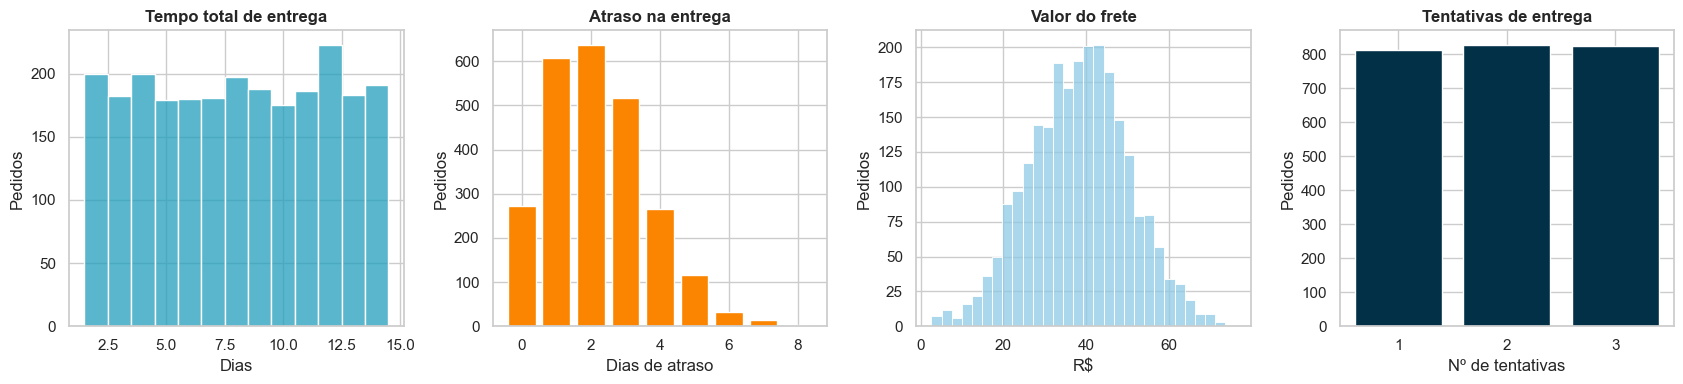

Atrasados: 89.0% | atraso >= 3 dias: 38.5% | atraso médio (entre atrasados): 2.46 dias
Mais de uma tentativa: 67.1% | 3 tentativas: 33.5%


In [13]:
# Visão geral da operação logística
fig, axes = plt.subplots(1, 4, figsize=(17, 4))

sns.histplot(df["tempo_entrega_dias"], bins=13, discrete=True, ax=axes[0], color="#219ebc")
axes[0].set(title="Tempo total de entrega", xlabel="Dias", ylabel="Pedidos")

contagem_atraso = df["atraso_entrega_dias"].value_counts().sort_index()
axes[1].bar(contagem_atraso.index, contagem_atraso.values, color="#fb8500")
axes[1].set(title="Atraso na entrega", xlabel="Dias de atraso", ylabel="Pedidos")

sns.histplot(df["valor_frete"], bins=30, ax=axes[2], color="#8ecae6")
axes[2].set(title="Valor do frete", xlabel="R$", ylabel="Pedidos")

contagem_tentativas = df["tentativas_entrega"].value_counts().sort_index()
axes[3].bar(contagem_tentativas.index.astype(str), contagem_tentativas.values, color="#023047")
axes[3].set(title="Tentativas de entrega", xlabel="Nº de tentativas", ylabel="Pedidos")

plt.tight_layout(); plt.show()

print(f"Atrasados: {df['atrasado'].mean():.1%} | atraso >= 3 dias: {(df['atraso_entrega_dias'] >= 3).mean():.1%} "
      f"| atraso médio (entre atrasados): {df.loc[df['atrasado'] == 1, 'atraso_entrega_dias'].mean():.2f} dias")
print(f"Mais de uma tentativa: {df['multiplas_tentativas'].mean():.1%} | 3 tentativas: {(df['tentativas_entrega'] == 3).mean():.1%}")

**O que investigamos:** o perfil geral da operação de entrega.

**Fatos**

- **~89% dos pedidos chegam com atraso** (>0 dia) e **~38% com 3 dias ou mais**. A média de atraso é 2,2 dias.
- O **tempo total de entrega** é praticamente uniforme entre 2 e 14 dias (mediana 8): não há uma "faixa típica", todas as durações aparecem com frequência similar.
- As **tentativas de entrega** estão divididas quase igualmente em 1, 2 e 3 (≈ 33% cada): **dois em cada três pedidos precisam de mais de uma tentativa**.
- O frete tem distribuição aproximadamente simétrica, centrada em ~R$ 38.

**Interpretação.** Como operação, a logística é **crônica e generalizada** no atraso (não é problema de uma cauda), e a taxa de reentrega é muito alta para uma operação saudável. Distribuições muito "planas" (uniformes) como as de tempo e tentativas também sugerem cautela: parecem pouco com dados operacionais reais (que costumam ter concentração e cauda longa). **Hipótese:** a base é sintética ou muito tratada — o que explica a ausência de padrões regionais mais adiante.

## 06. Análise temporal da logística

> **Esta análise não pode ser realizada com a base disponível porque não existem informações suficientes para calcular essa métrica.**

A base não possui nenhuma coluna de data (pedido, postagem, entrega). Portanto **não é possível** analisar evolução de volume, sazonalidade, tendência, períodos críticos ou médias móveis.

**Cuidado:** `id_pedido` é sequencial (50001–52500), mas isso **não deve ser usado como proxy de tempo**: não há evidência no dicionário de que a ordem do ID reflita a ordem cronológica. Como verificação rápida e honesta, abaixo medimos se existe algum padrão ao longo de `id_pedido`.

In [14]:
# Checagem de sanidade (NÃO é análise temporal): o atraso varia com a ordem do id_pedido?
rho, p = stats.spearmanr(df["id_pedido"], df["atraso_entrega_dias"])
print(f"Spearman(id_pedido, atraso_entrega_dias) = {rho:.3f} (p = {p:.3f})")

Spearman(id_pedido, atraso_entrega_dias) = -0.021 (p = 0.308)


**Fato.** Não há relação entre `id_pedido` e atraso. Mesmo que houvesse, não poderíamos atribuí-la ao tempo. Recomendação para a próxima iteração de dados: **incluir data do pedido, de postagem e de entrega** — isso abriria sazonalidade, SLA real e análise por etapa.

## 07. Análise geográfica / regional

**Escopo disponível:** apenas `regiao_cliente` (5 macrorregiões, região do **cliente**). Não há estado, cidade, origem ou rota. **O que investigamos:** a operação logística e o NPS diferem entre regiões?

In [15]:
def resumo_logistico(quadro: pd.DataFrame, by) -> pd.DataFrame:
    """Agregados logísticos e de satisfação para qualquer dimensão de agrupamento."""
    grouped = quadro.groupby(by, observed=True)
    out = grouped.agg(
        pedidos=("id_pedido", "count"),
        media_dias_entrega=("tempo_entrega_dias", "mean"),
        desvio_dias_entrega=("tempo_entrega_dias", "std"),
        taxa_atraso=("atrasado", "mean"),
        media_dias_atraso=("atraso_entrega_dias", "mean"),
        p90_dias_atraso=("atraso_entrega_dias", lambda s: s.quantile(0.9)),
        media_tentativas=("tentativas_entrega", "mean"),
        taxa_multiplas_tentativas=("multiplas_tentativas", "mean"),
        media_frete=("valor_frete", "mean"),
        nps_medio=("nota_nps", "mean"),
        taxa_detratores=("eh_detrator", "mean"),
    )
    out["participacao_pedidos"] = out["pedidos"] / out["pedidos"].sum()
    for coluna in ["taxa_atraso", "taxa_multiplas_tentativas", "taxa_detratores", "participacao_pedidos"]:
        out[coluna] = out[coluna] * 100
    return out

resumo_regioes = resumo_logistico(df, "regiao_cliente").sort_values("media_dias_atraso", ascending=False)
resumo_regioes

,pedidos,media_dias_entrega,desvio_dias_entrega,taxa_atraso,media_dias_atraso,p90_dias_atraso,media_tentativas,taxa_multiplas_tentativas,media_frete,nps_medio,taxa_detratores,participacao_pedidos
regiao_cliente,,,,,,,,,,,,
Centro-Oeste,461,7.89,3.78,88.07,2.24,4.00,1.99,67.46,37.89,4.20,79.61,18.70
Sudeste,514,8.21,3.77,90.86,2.21,4.00,2.03,68.29,38.56,4.39,79.18,20.85
Nordeste,475,8.20,3.89,89.89,2.17,4.00,2.02,68.00,37.42,4.44,79.16,19.27
Sul,513,8.08,3.76,87.91,2.17,4.00,2.00,65.69,38.49,4.48,78.36,20.81
Norte,502,7.73,3.66,88.05,2.15,4.00,1.98,65.94,39.01,4.38,79.08,20.37


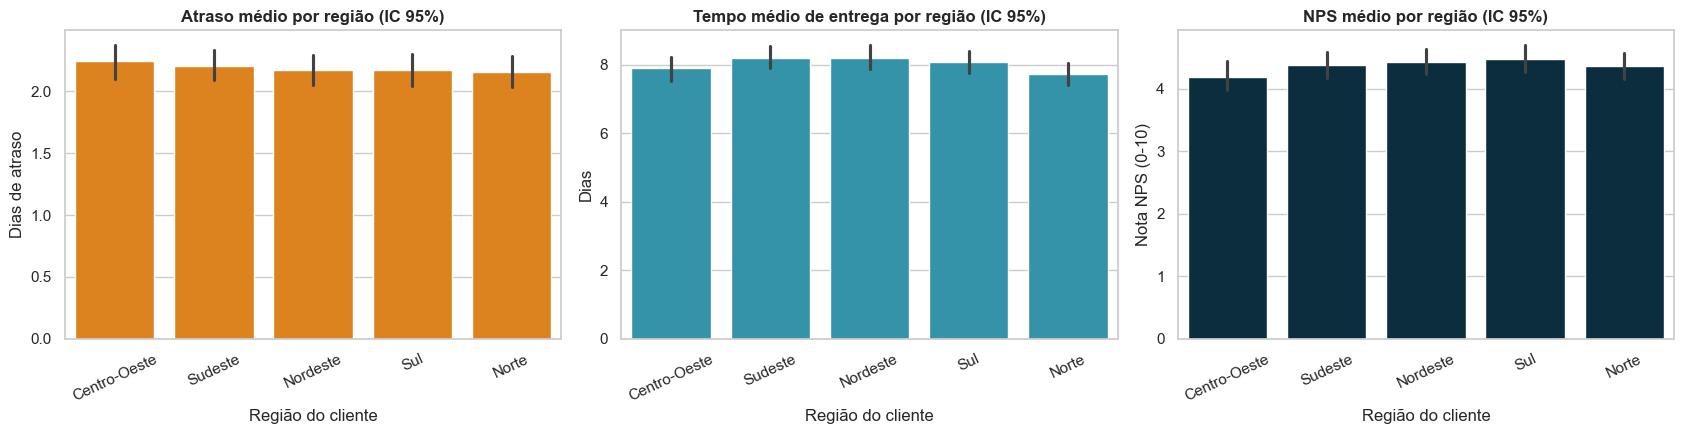

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ordem_regioes = resumo_regioes.sort_values("media_dias_atraso", ascending=False).index

sns.barplot(data=df, x="regiao_cliente", y="atraso_entrega_dias", order=ordem_regioes, ax=axes[0], color="#fb8500", errorbar=("ci", 95))
axes[0].set(title="Atraso médio por região (IC 95%)", xlabel="Região do cliente", ylabel="Dias de atraso")

sns.barplot(data=df, x="regiao_cliente", y="tempo_entrega_dias", order=ordem_regioes, ax=axes[1], color="#219ebc", errorbar=("ci", 95))
axes[1].set(title="Tempo médio de entrega por região (IC 95%)", xlabel="Região do cliente", ylabel="Dias")

sns.barplot(data=df, x="regiao_cliente", y="nota_nps", order=ordem_regioes, ax=axes[2], color="#023047", errorbar=("ci", 95))
axes[2].set(title="NPS médio por região (IC 95%)", xlabel="Região do cliente", ylabel="Nota NPS (0-10)")

for ax in axes:
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

In [17]:
# Diferenças entre regiões são estatisticamente distinguíveis? (Kruskal-Wallis: não assume normalidade)
for coluna in ["atraso_entrega_dias", "tempo_entrega_dias", "valor_frete", "tentativas_entrega", "nota_nps"]:
    grupos = [g[coluna].values for _, g in df.groupby("regiao_cliente")]
    h, p = stats.kruskal(*grupos)
    print(f"{coluna:<24} H = {h:5.2f}  p = {p:.3f}  -> {'diferença significativa' if p < 0.05 else 'sem diferença significativa'}")

atraso_entrega_dias      H =  2.01  p = 0.733  -> sem diferença significativa
tempo_entrega_dias       H =  6.11  p = 0.191  -> sem diferença significativa
valor_frete              H =  4.30  p = 0.368  -> sem diferença significativa
tentativas_entrega       H =  1.29  p = 0.862  -> sem diferença significativa
nota_nps                 H =  3.58  p = 0.466  -> sem diferença significativa


**O que os dados mostram (fatos)**

- As cinco regiões têm volume parecido (461 a 514 pedidos; cerca de 19%–21% cada).
- O atraso médio varia só de **2,15 a 2,24 dias**; o tempo médio de entrega, de **7,7 a 8,2 dias**; o NPS médio, de **4,2 a 4,5**.
- O teste de Kruskal-Wallis **não encontra diferença significativa** entre regiões em atraso (p ≈ 0,73), tempo de entrega (p ≈ 0,19) nem NPS (p ≈ 0,47).

**Interpretação.** A região **não explica** os problemas logísticos nem o NPS. Os rankings regionais acima existem numericamente, mas as diferenças são do tamanho do ruído amostral: **não devemos eleger "melhor" ou "pior" região**. O problema é **sistêmico**, não geográfico.

**Limitação.** A região do cliente é uma agregação grossa; diferenças em estado, cidade, CD ou rota (que não existem na base) poderiam existir e estar escondidas.

**Recomendação.** Não direcionar investimento logístico por macrorregião com base nesta base. Priorizar, quando possível, dados em nível de cidade/CEP.

## 08. Análise por Centro de Distribuição

> **Esta análise não pode ser realizada com a base disponível porque não existem informações suficientes para calcular essa métrica.**

Não há coluna de CD, unidade, origem ou hub. Não é possível comparar volume movimentado, taxa de atraso, variabilidade ou gargalos por CD.

## 09. Análise de produtos

> **Esta análise não pode ser realizada com a base disponível porque não existem informações suficientes para calcular essa métrica.**

Não há produto, categoria ou SKU. O mais próximo disponível é o **perfil do pedido** (`qtd_itens` e `valor_pedido`). Abaixo testamos se pedidos maiores/mais caros sofrem mais com a logística — **isto não substitui uma análise por produto.**

In [18]:
perfil_pedido = df.assign(
    quintil_valor_pedido=pd.qcut(df["valor_pedido"], 5, labels=["Q1 (menor)", "Q2", "Q3", "Q4", "Q5 (maior)"])
)
tabela_perfil = pd.concat({
    "por valor do pedido": resumo_logistico(perfil_pedido, "quintil_valor_pedido")[
        ["pedidos", "media_dias_entrega", "taxa_atraso", "media_dias_atraso", "nps_medio"]
    ].rename_axis("segmento"),
    "por quantidade de itens": resumo_logistico(df, "qtd_itens")[
        ["pedidos", "media_dias_entrega", "taxa_atraso", "media_dias_atraso", "nps_medio"]
    ].rename_axis("segmento"),
})
tabela_perfil

pedidos  media_dias_entrega  taxa_atraso  media_dias_atraso  nps_medio
                        segmento                                                                          
por valor do pedido     Q1 (menor)      493                8.14        87.42               2.12       4.19
                        Q2              493                7.87        88.64               2.20       4.43
                        Q3              493                8.09        89.25               2.21       4.40
                        Q4              493                8.21        89.66               2.24       4.29
                        Q5 (maior)      493                7.80        89.86               2.17       4.58
por quantidade de itens 1               403                8.17        90.07               2.29       4.32
                        2               410                7.73        86.59               2.16       4.47
                        3               457                7.91        88.62               2.16       4.35
                        4               403                8.04        88.34               2.18       4.21
                        5               398                8.02        90.45               2.17       4.42
                        6               394                8.30        89.85               2.18       4.51

**Fato.** Entre os quintis de valor do pedido e entre as quantidades de itens (1 a 6), o atraso médio fica em torno de 2,1–2,3 dias e o tempo de entrega entre ~7,7 e 8,3 dias, sem tendência. O NPS médio varia de 4,2 a 4,6.
**Interpretação.** O tamanho/valor do pedido **não parece afetar** a logística nem a satisfação nesta base. Pedidos mais caros não recebem tratamento logístico diferente.

## 10. Análise de transporte e entrega

**Escopo.** Não existem transportadora nem modalidade. Existem **`tentativas_entrega`** (tentativas), **`valor_frete`** (frete) e **`tempo_entrega_dias`**. A análise abaixo se limita a essas variáveis.

> **Desempenho por transportadora e por modalidade não pode ser realizado com a base disponível porque não existem informações suficientes para calcular essa métrica.**

,pedidos,media_dias_entrega,media_dias_atraso,taxa_atraso,media_frete,nps_medio,taxa_detratores
tentativas_entrega,,,,,,,
1,812,8.12,2.14,88.79,38.48,4.36,78.45
2,828,8.05,2.25,89.61,37.91,4.26,81.88
3,825,7.90,2.17,88.48,38.49,4.52,76.85


,pedidos,media_dias_entrega,media_dias_atraso,nps_medio,taxa_detratores
faixa_frete,,,,,
<=20,154,7.79,2.27,4.36,80.52
20-30,460,8.20,2.21,4.42,78.04
30-40,720,8.08,2.08,4.56,77.08
40-50,730,7.95,2.27,4.26,80.68
>50,401,7.94,2.19,4.24,80.30


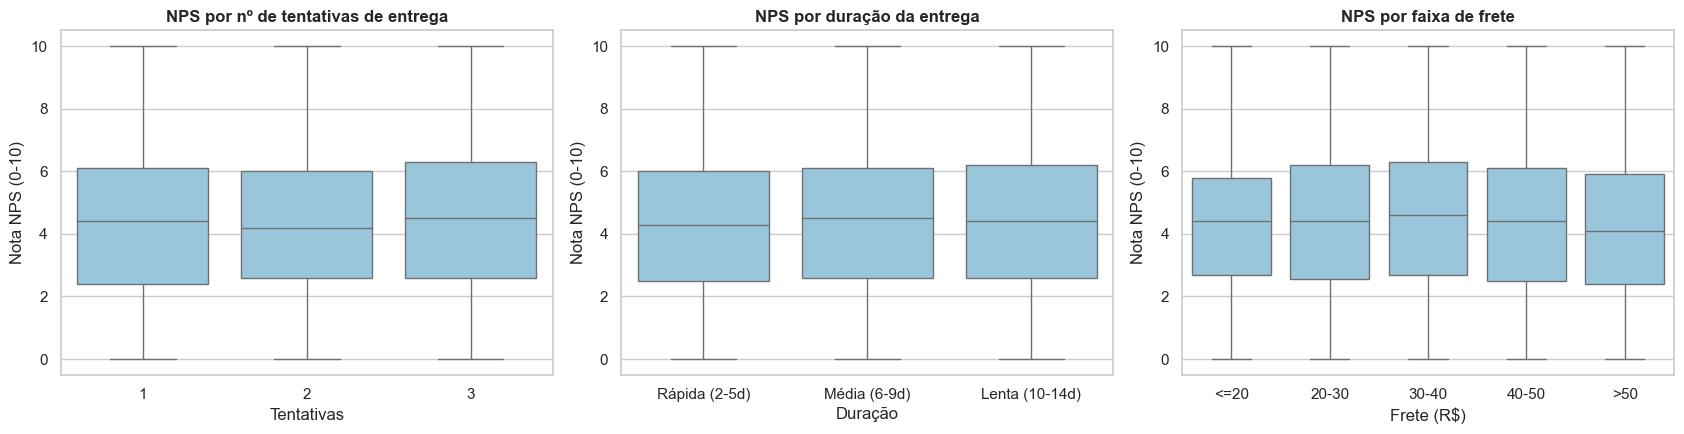

Spearman(tentativas_entrega, nota_nps) = +0.026  (p = 0.196)
Spearman(tempo_entrega_dias, nota_nps) = -0.001  (p = 0.953)
Spearman(valor_frete, nota_nps) = -0.039  (p = 0.053)


In [19]:
resumo_tentativas = resumo_logistico(df, "tentativas_entrega")[
    ["pedidos", "media_dias_entrega", "media_dias_atraso", "taxa_atraso", "media_frete", "nps_medio", "taxa_detratores"]
]
display(resumo_tentativas)

faixa_frete = pd.cut(df["valor_frete"], bins=[0, 20, 30, 40, 50, np.inf], labels=["<=20", "20-30", "30-40", "40-50", ">50"])
resumo_frete = resumo_logistico(df.assign(faixa_frete=faixa_frete), "faixa_frete")[
    ["pedidos", "media_dias_entrega", "media_dias_atraso", "nps_medio", "taxa_detratores"]
]
display(resumo_frete)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=df, x="tentativas_entrega", y="nota_nps", ax=axes[0], color="#8ecae6")
axes[0].set(title="NPS por nº de tentativas de entrega", xlabel="Tentativas", ylabel="Nota NPS (0-10)")

sns.boxplot(data=df, x="faixa_duracao_entrega", y="nota_nps", ax=axes[1], color="#8ecae6")
axes[1].set(title="NPS por duração da entrega", xlabel="Duração", ylabel="Nota NPS (0-10)")

sns.boxplot(data=df.assign(faixa_frete=faixa_frete), x="faixa_frete", y="nota_nps", ax=axes[2], color="#8ecae6")
axes[2].set(title="NPS por faixa de frete", xlabel="Frete (R$)", ylabel="Nota NPS (0-10)")
plt.tight_layout(); plt.show()

for coluna in ["tentativas_entrega", "tempo_entrega_dias", "valor_frete"]:
    rho, p = stats.spearmanr(df[coluna], df["nota_nps"])
    print(f"Spearman({coluna}, nota_nps) = {rho:+.3f}  (p = {p:.3f})")

**Fatos**

- O NPS médio é praticamente igual para 1, 2 e 3 tentativas (≈ 4,3–4,5) e o atraso médio também (≈ 2,1–2,3 dias). A correlação com o NPS é ≈ +0,03 (não significativa).
- O **tempo total de entrega** não tem relação com o NPS (Spearman ≈ 0,00): entregar em 2 ou em 14 dias leva ao mesmo NPS médio (≈ 4,2–4,7 em todas as durações).
- O **frete** tem correlação muito fraca e marginal com o NPS (≈ −0,04; p ≈ 0,05). A diferença entre faixas é pequena.

**Interpretação (importante).** Contraintuitivamente, **demorar mais, precisar de mais tentativas ou pagar mais frete não explica o NPS** nesta base. O que importa (próximas seções) é o **atraso em relação ao prazo**, ou seja, o *descumprimento da expectativa*, e não a duração em si.

**Hipótese.** Se o cliente é informado de um prazo (14 dias, por exemplo) e recebe dentro dele, a duração absoluta pesa pouco. Isso reforça a importância de **prometer prazos realistas**. Não conseguimos validar isso porque o prazo prometido não existe na base.

**Recomendação.** Não priorizar redução de tentativas ou do frete **como alavanca de NPS** com base nesta evidência; investigar se tentativas importam por outros motivos (custo operacional, por exemplo).

## 11. Análise de estoque

> **Esta análise não pode ser realizada com a base disponível porque não existem informações suficientes para calcular essa métrica.**

Não há nível de estoque, ruptura, cobertura ou demanda por produto/região. Nenhuma métrica de estoque foi inventada.

## 12. Correlações e relações entre variáveis

**O que investigamos:** quais variáveis logísticas (e de contexto) se associam à satisfação? Usamos **Spearman** (robusto a variáveis discretas e a relações não lineares monotônicas). Correlação **não** implica causalidade.

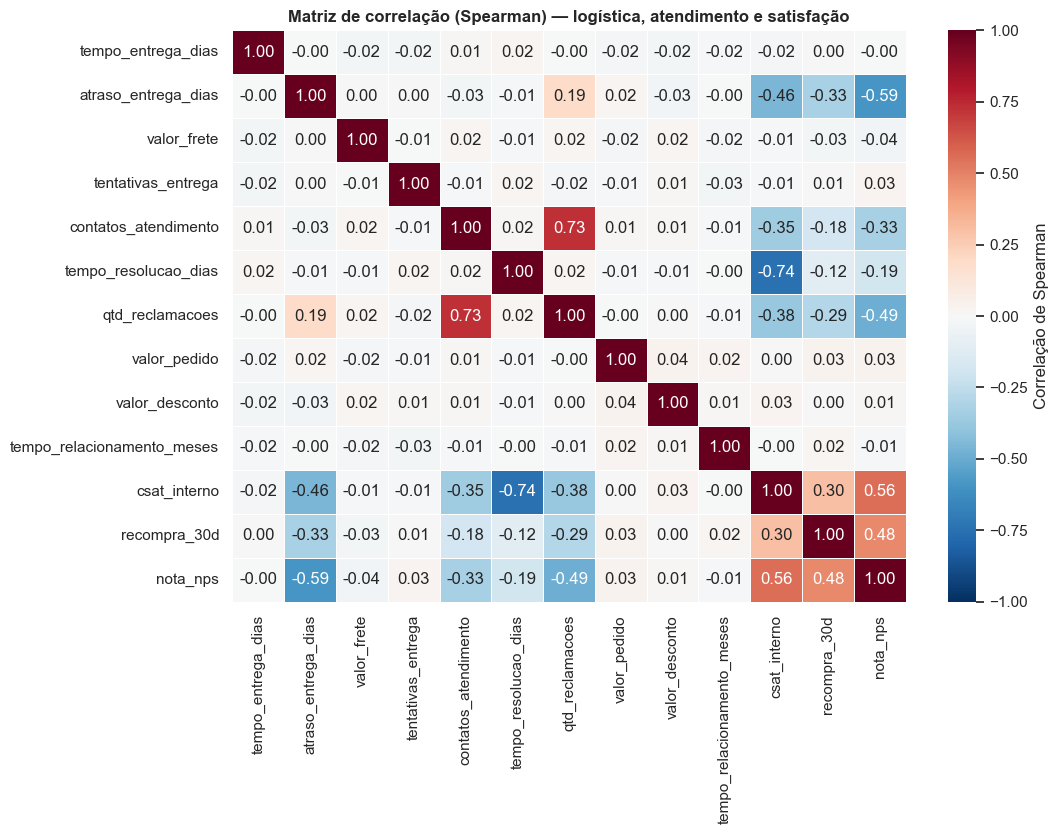

,spearman_vs_nota_nps
atraso_entrega_dias,-0.59
qtd_reclamacoes,-0.49
contatos_atendimento,-0.33
tempo_resolucao_dias,-0.19
valor_frete,-0.04
tempo_relacionamento_meses,-0.01
tempo_entrega_dias,-0.00
valor_desconto,0.01
tentativas_entrega,0.03
valor_pedido,0.03


In [20]:
cols_corr = COLS_LOGISTICA + ["contatos_atendimento", "tempo_resolucao_dias", "qtd_reclamacoes",
                              "valor_pedido", "valor_desconto", "tempo_relacionamento_meses", "csat_interno",
                              "recompra_30d", "nota_nps"]
matriz_corr = df[cols_corr].corr(method="spearman")

plt.figure(figsize=(11, 8.5))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "Correlação de Spearman"})
plt.title("Matriz de correlação (Spearman) — logística, atendimento e satisfação")
plt.tight_layout(); plt.show()

matriz_corr["nota_nps"].drop("nota_nps").sort_values().to_frame("spearman_vs_nota_nps")

**Fatos**

- **`atraso_entrega_dias` é a variável logística dominante: ρ ≈ −0,59 com o NPS.**
- As demais variáveis logísticas (`tempo_entrega_dias`, `valor_frete`, `tentativas_entrega`) ficam entre −0,04 e +0,03 — praticamente zero.
- `tempo_entrega_dias` e `atraso_entrega_dias` têm correlação ≈ 0 entre si, o que reforça a dúvida de definição da seção 4.2.
- Variáveis de atendimento também se associam ao NPS: `qtd_reclamacoes` (ρ ≈ −0,49), `contatos_atendimento` (ρ ≈ −0,33), `tempo_resolucao_dias` (ρ ≈ −0,19).
- `csat_interno` (ρ ≈ +0,56) e `recompra_30d` (ρ ≈ +0,48) se associam positivamente ao NPS, mas são medidas de satisfação/resultado, não causas.
- Atraso se associa a **mais reclamações** (ρ ≈ +0,19), mas quase não se associa a mais contatos com o atendimento (ρ ≈ −0,03).

**Interpretação.** A informação logística útil se concentra em **uma única variável: o atraso**. As variáveis de pedido e de cliente (`valor_pedido`, `valor_desconto`, `tempo_relacionamento_meses`, idade) têm correlação ≈ 0 com o NPS.

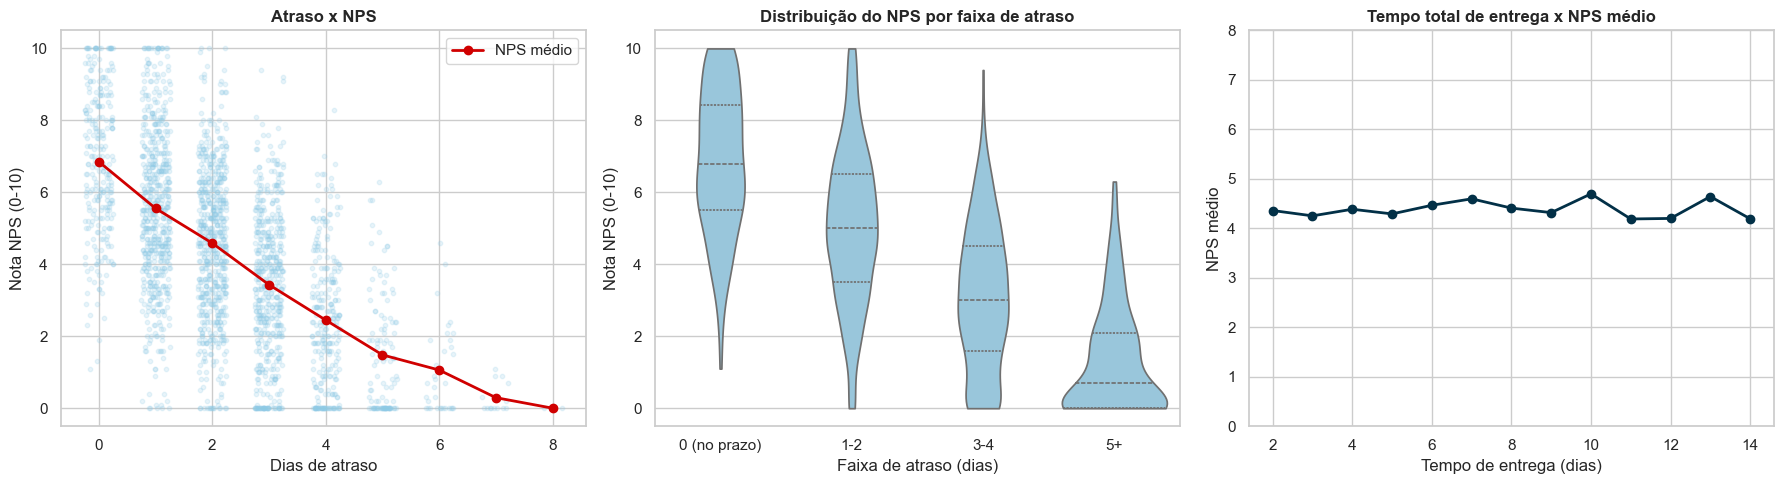

Ajuste linear simples: NPS ≈ 6.64 -1.03 x dias_de_atraso  (cada dia de atraso ≈ -1.03 ponto de NPS, associação — não causalidade)


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Atraso x NPS: dispersão com ruido + média por dia de atraso
ruido = np.random.default_rng(RANDOM_STATE).uniform(-0.25, 0.25, len(df))
axes[0].scatter(df["atraso_entrega_dias"] + ruido, df["nota_nps"], alpha=0.2, s=10, color="#8ecae6")
media_por_atraso = df.groupby("atraso_entrega_dias")["nota_nps"].mean()
axes[0].plot(media_por_atraso.index, media_por_atraso.values, "o-", color="#d00000", lw=2, label="NPS médio")
axes[0].set(title="Atraso x NPS", xlabel="Dias de atraso", ylabel="Nota NPS (0-10)")
axes[0].legend()

# (b) Distribuição do NPS por gravidade do atraso
sns.violinplot(data=df, x="faixa_atraso", y="nota_nps", ax=axes[1], color="#8ecae6", cut=0, inner="quartile")
axes[1].set(title="Distribuição do NPS por faixa de atraso", xlabel="Faixa de atraso (dias)", ylabel="Nota NPS (0-10)")

# (c) Tempo de entrega x NPS (para contraste)
media_por_tempo = df.groupby("tempo_entrega_dias")["nota_nps"].mean()
axes[2].plot(media_por_tempo.index, media_por_tempo.values, "o-", color="#023047", lw=2)
axes[2].set_ylim(0, 8)
axes[2].set(title="Tempo total de entrega x NPS médio", xlabel="Tempo de entrega (dias)", ylabel="NPS médio")
plt.tight_layout(); plt.show()

inclinacao, intercepto = np.polyfit(df["atraso_entrega_dias"], df["nota_nps"], 1)
print(f"Ajuste linear simples: NPS ≈ {intercepto:.2f} {inclinacao:+.2f} x dias_de_atraso  (cada dia de atraso ≈ {inclinacao:.2f} ponto de NPS, associação — não causalidade)")

**O que os dados mostram**

- **Fato:** o NPS médio cai de forma quase linear com cada dia de atraso: de **6,85 (sem atraso)** para 5,55 (1 dia), 4,59 (2), 3,43 (3), 2,45 (4), 1,48 (5) e próximo de 0 a partir de 7 dias. Cada dia adicional se associa a **≈ −1 ponto** de NPS.
- **Fato:** o gráfico da direita contrasta: variar o **tempo total** de 2 a 14 dias não altera o NPS médio.
- **Interpretação:** o cliente reage ao **descumprimento do prazo**, não à duração da entrega. Isso é coerente com a teoria de expectativa: o que machuca é ser "enganado", e não esperar.
- **Hipótese:** o impacto do atraso pode passar parcialmente pelas reclamações (atraso → mais reclamações → NPS menor). Dá para ver a primeira parte da cadeia (atraso ↔ reclamações, ρ ≈ +0,19), mas **a base não permite testar causalidade nem mediação**.

In [22]:
# O atraso "vaza" para outros indicadores de satisfação e de atendimento?
cruzamento_atraso = df.groupby("faixa_atraso", observed=True).agg(
    pedidos=("id_pedido", "count"),
    nps_medio=("nota_nps", "mean"),
    csat_medio=("csat_interno", "mean"),
    reclamacoes_medias=("qtd_reclamacoes", "mean"),
    contatos_medios=("contatos_atendimento", "mean"),
    taxa_recompra=("recompra_30d", "mean"),
)
cruzamento_atraso["taxa_recompra"] *= 100
cruzamento_atraso

,pedidos,nps_medio,csat_medio,reclamacoes_medias,contatos_medios,taxa_recompra
faixa_atraso,,,,,,
0 (no prazo),272,6.85,4.76,2.99,1.57,33.82
1-2,1245,5.06,3.42,4.18,1.54,9.08
3-4,782,3.10,2.00,4.41,1.48,0.64
5+,166,1.27,0.78,4.60,1.45,0.00


**Fatos.** Com o aumento do atraso, caem o **CSAT interno** (de 4,8 sem atraso para 3,4 → 2,0 → 0,8 nas faixas 1–2, 3–4 e 5+ dias) e a **recompra em 30 dias** (de ~34% sem atraso para ~9% com 1–2 dias, < 1% com 3–4 dias e 0% com 5+). As reclamações médias sobem de ~3,0 para ~4,2–4,6.
**Interpretação.** O atraso aparece associado, de forma coerente, a **várias métricas de satisfação ao mesmo tempo** (NPS, CSAT, recompra, reclamações). Isso reforça (mas não prova) que o atraso é um sinal de risco importante. **Impacto financeiro potencial:** o efeito sobre a recompra é o argumento mais direto para a diretoria.

## 13. Identificação de gargalos logísticos

**O que investigamos:** onde estão os maiores atrasos e os maiores focos de detratores. Como não há CD, produto, transportadora, tempo por etapa ou período, os "rankings" possíveis são **por região, por faixa de atraso e por perfil de entrega**. Gargalos *por etapa* (separação, expedição, trânsito, última milha) **não podem ser identificados**: só há o tempo total.

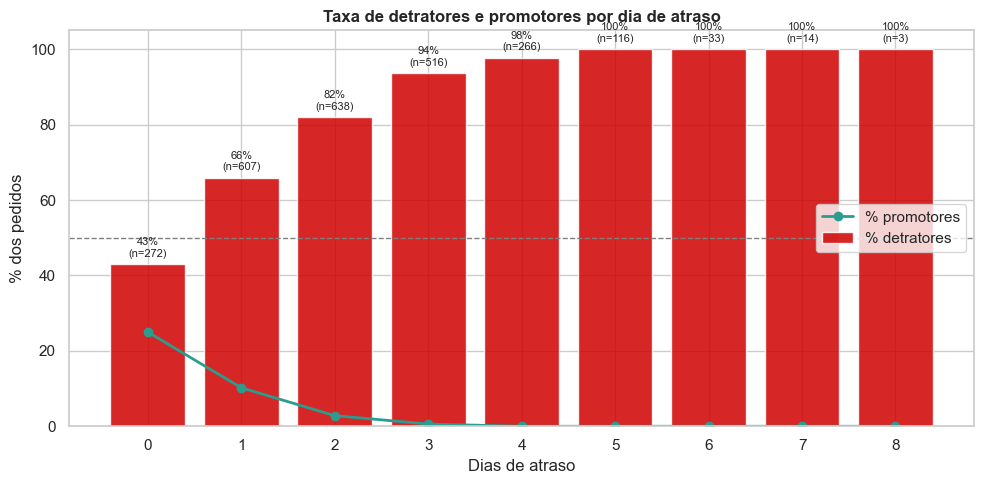

,pedidos,nps_medio,taxa_detratores,taxa_promotores
atraso_entrega_dias,,,,
0,272,6.90,43.00,25.00
1,607,5.60,65.90,10.20
2,638,4.60,82.00,2.80
3,516,3.40,93.60,0.60
4,266,2.40,97.70,0.00
5,116,1.50,100.00,0.00
6,33,1.10,100.00,0.00
7,14,0.30,100.00,0.00
8,3,0.00,100.00,0.00


In [23]:
# Ponto de ruptura: taxa de detratores por dia de atraso
por_atraso = df.groupby("atraso_entrega_dias").agg(
    pedidos=("id_pedido", "count"),
    nps_medio=("nota_nps", "mean"),
    taxa_detratores=("eh_detrator", "mean"),
    taxa_promotores=("classe_nps", lambda s: (s == "Promotor").mean()),
)
por_atraso[["taxa_detratores", "taxa_promotores"]] *= 100

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(por_atraso.index, por_atraso["taxa_detratores"], color="#d00000", alpha=0.85, label="% detratores")
ax1.plot(por_atraso.index, por_atraso["taxa_promotores"], "o-", color="#2a9d8f", lw=2, label="% promotores")
ax1.axhline(50, color="grey", ls="--", lw=1)
ax1.set(title="Taxa de detratores e promotores por dia de atraso", xlabel="Dias de atraso", ylabel="% dos pedidos", ylim=(0, 105))
ax1.set_xticks(por_atraso.index)
for x, y, n in zip(por_atraso.index, por_atraso["taxa_detratores"], por_atraso["pedidos"]):
    ax1.text(x, y + 2, f"{y:.0f}%\n(n={n})", ha="center", fontsize=8)
ax1.legend(loc="center right")
plt.tight_layout(); plt.show()

por_atraso.round(1)

**Fatos**

- Mesmo **sem atraso**, **43% dos clientes são detratores** (e 25% são promotores): a satisfação já é baixa no melhor cenário.
- Com **1 dia de atraso**, a taxa de detratores vai a **66%** (e promotores caem a 10%); com **2 dias**, **82%**; com **3 dias**, **94%**; **a partir de 4 dias, ≥ 98%**.
- A partir de **3 dias de atraso** praticamente não existem promotores (< 1%).

**Interpretação — "ponto de ruptura".** Não há um degrau único; a deterioração é **contínua**, mas o **primeiro dia de atraso** já é o maior salto individual em detratores (+23 p.p.), seguido do 2º dia (+16 p.p.); entre **2 e 3 dias** de atraso a esmagadora maioria dos clientes já é detratora. Em termos operacionais: **1 dia de atraso já é inaceitável para a experiência; 3 dias é praticamente "perda total"**.

**Hipótese.** Prazos prometidos mais longos, ou mais conservadores, poderiam transformar parte dos atrasos "de 1–2 dias" em entregas no prazo. Não dá para testar sem o campo de prazo prometido.

Ranking de regiões por % de detratores (diferenças NÃO significativas — ver seção 07):


,pedidos,taxa_atraso,media_dias_atraso,p90_dias_atraso,taxa_detratores
regiao_cliente,,,,,
Centro-Oeste,461,88.07,2.24,4.00,79.61
Sudeste,514,90.86,2.21,4.00,79.18
Nordeste,475,89.89,2.17,4.00,79.16
Norte,502,88.05,2.15,4.00,79.08
Sul,513,87.91,2.17,4.00,78.36


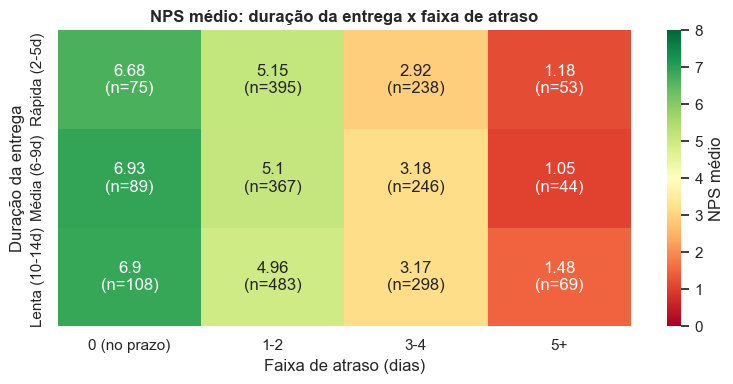

In [24]:
# Rankings possíveis com os dados: região x gravidade do atraso
ranking_regioes = resumo_regioes[["pedidos", "taxa_atraso", "media_dias_atraso", "p90_dias_atraso", "taxa_detratores"]] \
    .sort_values("taxa_detratores", ascending=False)
print("Ranking de regiões por % de detratores (diferenças NÃO significativas — ver seção 07):")
display(ranking_regioes)

# Perfil de entrega: duração x faixa de atraso (NPS médio)
mapa_calor = df.pivot_table(index="faixa_duracao_entrega", columns="faixa_atraso", values="nota_nps", aggfunc="mean", observed=True)
contagem = df.pivot_table(index="faixa_duracao_entrega", columns="faixa_atraso", values="nota_nps", aggfunc="count", observed=True)

plt.figure(figsize=(8, 4))
sns.heatmap(mapa_calor, annot=mapa_calor.round(2).astype(str) + "\n(n=" + contagem.astype(str) + ")", fmt="", cmap="RdYlGn", vmin=0, vmax=8,
            cbar_kws={"label": "NPS médio"})
plt.title("NPS médio: duração da entrega x faixa de atraso")
plt.xlabel("Faixa de atraso (dias)") 
plt.ylabel("Duração da entrega")
plt.tight_layout() 
plt.show()

**Fatos.** Na tabela cruzada, **as colunas (atraso) mudam completamente o NPS, enquanto as linhas (duração) quase não mudam nada**: dentro de cada faixa de atraso, entregas rápidas, médias ou lentas têm NPS parecido. Os piores resultados (NPS ≈ 1) estão em atraso 5+, **independentemente** da duração.
**Interpretação.** Um pedido entregue em 10–14 dias **sem atraso** tem NPS ≈ 6,9, enquanto um pedido entregue em 2–5 dias **com 5+ dias de atraso** tem NPS ≈ 1,2. **Cumprir o prazo vale mais que ser rápido.**
**Limitação.** O gargalo por etapa, por CD ou por transportadora não pode ser identificado.

## 14. Segmentação logística

**O que investigamos:** quais segmentos concentram o maior **impacto** (muitos pedidos/detratores) com maior **problema** (alta taxa de detratores). Cruzamos **região × faixa de atraso** (20 segmentos), pois são as dimensões que existem.

- **Impacto** = participação do segmento no total de **detratores**.
- **Problema** = taxa de detratores dentro do segmento.

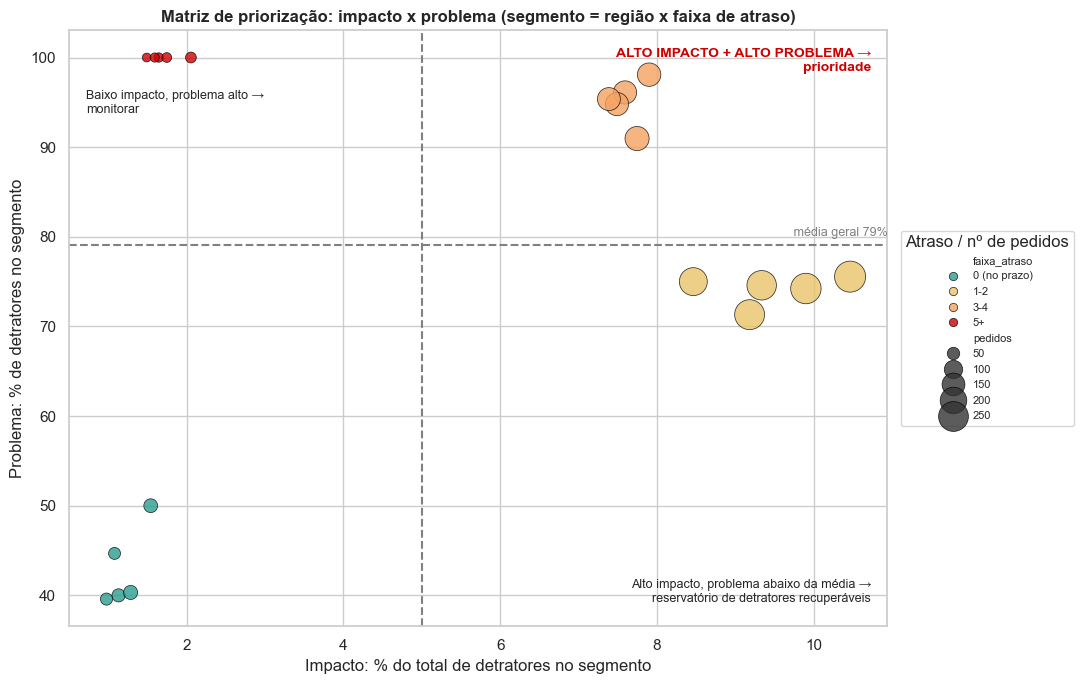

,segmento,pedidos,detratores,taxa_detratores,participacao_detratores,nps_medio
0,Norte | 3-4,157,154,98.09,7.90,2.91
1,Sudeste | 3-4,166,151,90.96,7.75,3.26
2,Centro-Oeste | 3-4,154,148,96.10,7.59,2.92
3,Nordeste | 3-4,154,146,94.81,7.49,3.12
4,Sul | 3-4,151,144,95.36,7.39,3.28


In [25]:
segmentos = (
    df.groupby(["regiao_cliente", "faixa_atraso"], observed=True)
    .agg(pedidos=("id_pedido", "count"), detratores=("eh_detrator", "sum"), nps_medio=("nota_nps", "mean"))
    .reset_index()
)
segmentos["taxa_detratores"] = segmentos["detratores"] / segmentos["pedidos"] * 100
segmentos["participacao_detratores"] = segmentos["detratores"] / segmentos["detratores"].sum() * 100
segmentos["segmento"] = segmentos["regiao_cliente"] + " | " + segmentos["faixa_atraso"].astype(str)

taxa_geral = df["eh_detrator"].mean() * 100
limiar_impacto = 100 / len(segmentos)  # participação "média" de um segmento (5%)

fig, ax = plt.subplots(figsize=(11, 7))
paleta = dict(zip(["0 (no prazo)", "1-2", "3-4", "5+"], ["#2a9d8f", "#e9c46a", "#f4a261", "#d00000"]))
sns.scatterplot(data=segmentos, x="participacao_detratores", y="taxa_detratores", hue=segmentos["faixa_atraso"].astype(str),
                size="pedidos", sizes=(40, 500), palette=paleta, ax=ax, alpha=0.8, edgecolor="black")
ax.axhline(taxa_geral, color="grey", ls="--"); ax.axvline(limiar_impacto, color="grey", ls="--")
ax.text(ax.get_xlim()[1], taxa_geral + 1, f" média geral {taxa_geral:.0f}%", ha="right", fontsize=9, color="grey")
ax.set(title="Matriz de priorização: impacto x problema (segmento = região x faixa de atraso)",
       xlabel="Impacto: % do total de detratores no segmento", ylabel="Problema: % de detratores no segmento")
ax.text(0.02, 0.90, "Baixo impacto, problema alto →\nmonitorar", transform=ax.transAxes, ha="left", va="top", fontsize=9)
ax.text(0.98, 0.04, "Alto impacto, problema abaixo da média →\nreservatório de detratores recuperáveis", transform=ax.transAxes, ha="right", fontsize=9)
ax.text(0.98, 0.97, "ALTO IMPACTO + ALTO PROBLEMA →\nprioridade", transform=ax.transAxes, ha="right", va="top", fontsize=10, fontweight="bold", color="#d00000")
ax.legend(title="Atraso / nº de pedidos", loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
plt.tight_layout(); plt.show()

prioritarios = segmentos[(segmentos["participacao_detratores"] >= limiar_impacto) & (segmentos["taxa_detratores"] >= taxa_geral)]
prioritarios.sort_values("participacao_detratores", ascending=False)[
    ["segmento", "pedidos", "detratores", "taxa_detratores", "participacao_detratores", "nps_medio"]
].reset_index(drop=True)

In [26]:
# Concentração por faixa de atraso (sem região): onde está o volume de detratores?
por_faixa = df.groupby("faixa_atraso", observed=True).agg(
    pedidos=("id_pedido", "count"), detratores=("eh_detrator", "sum"), taxa_detratores=("eh_detrator", "mean")
)
por_faixa["participacao_pedidos_faixa"] = por_faixa["pedidos"] / por_faixa["pedidos"].sum() * 100
por_faixa["participacao_detratores"] = por_faixa["detratores"] / por_faixa["detratores"].sum() * 100
por_faixa["taxa_detratores"] *= 100
display(por_faixa.round(1))

# Cenário ILUSTRATIVO (hipótese, não causalidade): se os pedidos atrasados tivessem a taxa de detratores dos pontuais
linha_base = df.loc[df["atraso_entrega_dias"] == 0, "eh_detrator"].mean()
atrasados = df[df["atraso_entrega_dias"] > 0]
evitaveis = (atrasados["eh_detrator"].mean() - linha_base) * len(atrasados)
print(f"Detratores totais: {df['eh_detrator'].sum():,} | Taxa entre pontuais (linha de base): {linha_base:.1%}")
print(f"Cenário ilustrativo: ~{evitaveis:,.0f} detratores a menos ({evitaveis / df['eh_detrator'].sum():.1%} do total) "
      f"se pedidos atrasados se comportassem como os pontuais.")

,pedidos,detratores,taxa_detratores,participacao_pedidos_faixa,participacao_detratores
faixa_atraso,,,,,
0 (no prazo),272,117,43.00,11.00,6.00
1-2,1245,923,74.10,50.50,47.40
3-4,782,743,95.00,31.70,38.10
5+,166,166,100.00,6.70,8.50


Detratores totais: 1,949 | Taxa entre pontuais (linha de base): 43.0%
Cenário ilustrativo: ~889 detratores a menos (45.6% do total) se pedidos atrasados se comportassem como os pontuais.


**Fatos**

- O quadrante **alto impacto + alto problema** é formado exatamente pelos **cinco segmentos "atraso de 3–4 dias" (um por região)**: cada um responde por ~7,4%–7,9% dos detratores e tem 91%–100% de detratores. A região apenas "move" o segmento dentro do mesmo grupo de atraso.
- Por faixa de atraso: **1–2 dias** concentra a maior parte dos pedidos (≈ 50%) e ≈ 47% dos detratores, com taxa de detratores de ~74% (perto da média geral de 79%); **3–4 dias** (≈ 32% dos pedidos) responde por ≈ 38% dos detratores e tem taxa de ~95%; **5+ dias** (≈ 7% dos pedidos) é 100% detratores, mas por ser pequeno responde por apenas ≈ 9% dos detratores.

**Interpretação.** O melhor ganho absoluto não está no pior caso (5+ dias, raro), e sim em **reduzir os atrasos "médios" de 1–4 dias, que são volumosos**: os de 3–4 dias são o foco mais crítico (volume alto + quase todos detratores) e os de 1–2 dias o maior reservatório de detratores "recuperáveis". O foco vale para **qualquer região**.

**Hipótese (cenário ilustrativo).** Se pedidos atrasados se comportassem como os pontuais, haveria cerca de **890 detratores a menos (≈ 46% do total)**. É um **teto otimista** baseado em associação, não em efeito causal; mesmo assim ilustra a ordem de grandeza.

**Segmentações por volume, eficiência ou variabilidade** (alto/baixo volume, CD eficiente etc.) **não podem ser realizadas** porque não existem CD, produto, transportadora ou período que permitam definir "volume" ou "eficiência" de uma unidade operacional.

# Principais Insights Logísticos

### Insight 1 — O atraso (não a duração) é o fator logístico que importa
- **Evidência:** Spearman atraso × NPS ≈ −0,59 contra ≈ 0,00 para o tempo total de entrega. NPS médio de 6,85 sem atraso, 4,59 com 2 dias e ≈ 1,5 com 5 dias; ≈ −1 ponto de NPS por dia de atraso.
- **Impacto potencial:** a logística pode proteger ou destruir a satisfação ao cumprir (ou não) o prazo, independentemente da velocidade.
- **Recomendação (a investigar):** priorizar o **cumprimento do prazo prometido** sobre a redução do tempo médio; avaliar prazos prometidos mais realistas.

### Insight 2 — O atraso é generalizado, não pontual
- **Evidência:** ≈ 89% dos pedidos têm atraso > 0; ≈ 38% têm 3 dias ou mais; média de 2,2 dias.
- **Impacto potencial:** ≈ 79% dos clientes são detratores e o NPS é ≈ −73; a operação convive com atraso como regra.
- **Recomendação:** tratar como problema **sistêmico de processo/promessa**, não de exceções. Validar com o time operacional como o prazo é calculado e prometido.

### Insight 3 — Há uma escalada rápida de detratores já no 1º dia de atraso
- **Evidência:** detratores sobem de 43% (sem atraso) para 66% (1 dia), 82% (2), 94% (3) e ≥ 98% (4+). Promotores caem de 25% para 10% já com 1 dia e quase desaparecem a partir de 3 dias.
- **Impacto potencial:** o "ponto de ruptura" está em **1 a 3 dias**; é onde a maior parte da base está.
- **Recomendação:** criar alertas operacionais por pedido **com 1 dia de atraso projetado**, com ação proativa (comunicação, compensação) antes do NPS.

### Insight 4 — Atraso se associa à queda de recompra e CSAT
- **Evidência:** recompra em 30 dias vai de ~34% (sem atraso) para ~9% (1–2 dias), < 1% (3–4) e 0% (5+). CSAT médio cai de 4,8 para 0,8 na pior faixa.
- **Impacto potencial:** o atraso se conecta a **receita futura**, não só a percepção.
- **Recomendação:** quantificar o valor de uma recompra perdida (LTV) e comparar com o custo de reduzir atrasos.

### Insight 5 — Região, tentativas, frete, tempo de entrega e perfil do pedido **não** explicam o NPS
- **Evidência:** Kruskal-Wallis entre regiões sem diferença significativa (atraso p ≈ 0,73; NPS p ≈ 0,47); correlações com o NPS de −0,04 a +0,03 para tentativas e frete; NPS ≈ constante por faixa de duração.
- **Impacto potencial:** evita investir em frentes com pouca evidência de retorno em satisfação.
- **Recomendação:** não segmentar ações de NPS por macrorregião, nem priorizar redução de tentativas/frete como alavanca de NPS, **com esta base**. Podem ter valor por custo ou outras métricas (não avaliadas).

### Insight 6 — Os problemas de dados limitam a análise logística
- **Evidência:** 119 pedidos têm atraso maior que o tempo de entrega (263 com ≥); `nota_nps` é decimal apesar do dicionário; não há datas, CD, produto, transportadora ou prazo prometido.
- **Impacto potencial:** sem prazo prometido e datas, não se calcula SLA real nem se localizam gargalos por etapa.
- **Recomendação:** solicitar ao dono dos dados: **data de pedido/postagem/entrega, prazo prometido, CD/origem, transportadora e modalidade**, e a definição exata de `atraso_entrega_dias`.

## 16. Variáveis relevantes para Machine Learning

### Possíveis features
| Variável | Motivo | Observação |
|---|---|---|
| `atraso_entrega_dias` (e `atrasado`, `faixa_atraso`) | Principal sinal logístico (ρ ≈ −0,59 com o NPS). | Disponível assim que a entrega ocorre, **antes** da pesquisa de NPS: boa para uso preventivo. |
| `qtd_reclamacoes` | ρ ≈ −0,49. | **Verificar o momento de registro**: se for posterior à entrega, ainda é útil; se for posterior ao NPS, é vazamento. |
| `contatos_atendimento`, `tempo_resolucao_dias` | ρ ≈ −0,33 e −0,19. | Mesma ressalva de timing. |
| `tempo_entrega_dias`, `tentativas_entrega`, `valor_frete`, `frete_pct_pedido` | Sinal marginal isolado. | Manter para testar interações e como "contexto"; esperar pouca importância. |
| `regiao_cliente` | Sem diferença significativa. | Baixa prioridade; manter se o modelo exigir. |

### Possíveis targets
| Target | Tipo | Comentário |
|---|---|---|
| `nota_nps` | Regressão (0–10) | Alvo principal sugerido pelo Tech Challenge. Nota é decimal. |
| `eh_detrator` (`nota_nps < 6,5`, premissa de arredondamento) | Classificação binária | Mais acionável ao negócio. **≈ 79% de positivos** (conforme a regra de arredondamento adotada): classe majoritária; avaliar com PR-AUC/recall, não só acurácia. |
| `classe_nps` (3 classes) | Classificação multiclasse | **Promotor ≈ 6%**: forte desbalanceamento; difícil de modelar. |

### Variáveis a evitar
| Variável | Motivo |
|---|---|
| `id_cliente`, `id_pedido` | Identificadores, sem poder preditivo; risco de memorização. |
| `csat_interno` | Medida de satisfação (ρ ≈ +0,56 com o NPS); se for coletada junto ou após a pesquisa, **vaza** o target. Usar só se disponível antes do NPS. |
| `recompra_30d` | Ocorre **após** o pedido (janela de 30 dias): é consequência do NPS/satisfação, não um preditor utilizável antes da pesquisa. **Vazamento temporal.** |
| `classe_nps`, `eh_detrator` | Derivadas do target. |
| `valor_pedido`, `valor_desconto`, `qtd_itens`, `idade_cliente`, `tempo_relacionamento_meses` | Correlação ≈ 0 com o NPS; não são "evitar" por vazamento, e sim candidatas a descarte por ruído (decidir em feature selection). |

## 17. Conclusão executiva

**1. Como está o cenário logístico?**
Ruim e generalizado: ≈ 89% dos pedidos chegam com atraso (média 2,2 dias) e dois em cada três precisam de mais de uma tentativa de entrega. O NPS é ≈ −73 (≈ 79% detratores).

**2. Principais problemas encontrados?**
O **descumprimento do prazo**. Cada dia de atraso se associa a cerca de −1 ponto de NPS, e os detratores passam de 43% (no prazo) para 66% (1 dia), 94% (3 dias) e ≥ 98% (4+).

**3. Onde estão os maiores gargalos?**
Nos **atrasos de 1 a 4 dias**, que concentram ≈ 82% dos pedidos e ≈ 85% dos detratores (os de 3–4 dias formam o quadrante prioritário). Gargalos por **etapa, CD, produto ou transportadora não podem ser identificados** — a base não tem essas informações.

**4. Quais regiões / CDs / produtos / períodos merecem atenção?**
Nenhuma região se destaca (diferenças não significativas). **CDs, produtos e períodos não existem na base.**

**5. Quais fatores parecem estar relacionados ao desempenho?**
Atraso (forte), reclamações e contatos com o atendimento (moderado, a verificar timing). **Não** parecem relacionados: duração da entrega, tentativas, frete, região, valor/tamanho do pedido.

**6. Quais ações poderiam ser investigadas?**
(i) revisar como o prazo prometido é definido; (ii) alerta proativo ao cliente já no 1º dia de atraso projetado; (iii) estimar o valor da recompra perdida por atraso; (iv) coletar datas, prazo prometido, CD e transportadora.

**7. Como a EDA prepara o Machine Learning?**
Mostra que o sinal logístico está concentrado em `atraso_entrega_dias`, identifica variáveis com risco de vazamento (`csat_interno`, `recompra_30d`), define targets viáveis (`nota_nps` em regressão; `eh_detrator` em classificação) e alerta para o desbalanceamento (≈ 79% detratores / ≈ 6% promotores). Um modelo simples deve ter bom desempenho e o ganho de modelos complexos deve ser medido com cautela.

### Limitações
- Dados **sem datas, prazo prometido, CD, produto, transportadora ou estoque** — 5 das análises solicitadas não foram possíveis.
- Inconsistência entre `atraso_entrega_dias` e `tempo_entrega_dias` (119 casos com atraso > tempo) e `nota_nps` decimal, ambos a validar com o dono dos dados.
- Associações observacionais: **não** provam causalidade.
- Distribuições muito uniformes e ausência de padrão regional sugerem que a base pode ser sintética ou muito tratada; conclusões devem ser confirmadas com dados reais antes de decisões de alto custo.